<xarray.Dataset> Size: 2GB
Dimensions:                  (time: 62, pressure: 2, y: 949, x: 739,
                              height0: 1, height2: 1, height_above_msl: 1,
                              height1: 1)
Coordinates:
  * time                     (time) datetime64[ns] 496B 2026-09-30T09:00:00 ....
  * pressure                 (pressure) float32 8B 850.0 925.0
  * y                        (y) float32 4kB -8.98e+05 -8.955e+05 ... 1.472e+06
  * x                        (x) float32 3kB 2.786e+05 2.811e+05 ... 2.124e+06
    longitude                (y, x) float64 6MB ...
    latitude                 (y, x) float64 6MB ...
  * height0                  (height0) float32 4B 2.0
  * height2                  (height2) float32 4B 10.0
  * height_above_msl         (height_above_msl) float32 4B 0.0
  * height1                  (height1) float32 4B 0.0
Data variables:
    forecast_reference_time  datetime64[ns] 8B ...
    projection_lambert       int32 4B ...
    x_wind_pl                (ti

/opt/homebrew/anaconda3/lib/python3.12/site-packages/shapely/creation.py:460: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, typ, out=out, **kwargs)
/opt/homebrew/anaconda3/lib/python3.12/site-packages/shapely/creation.py:460: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, typ, out=out, **kwargs)


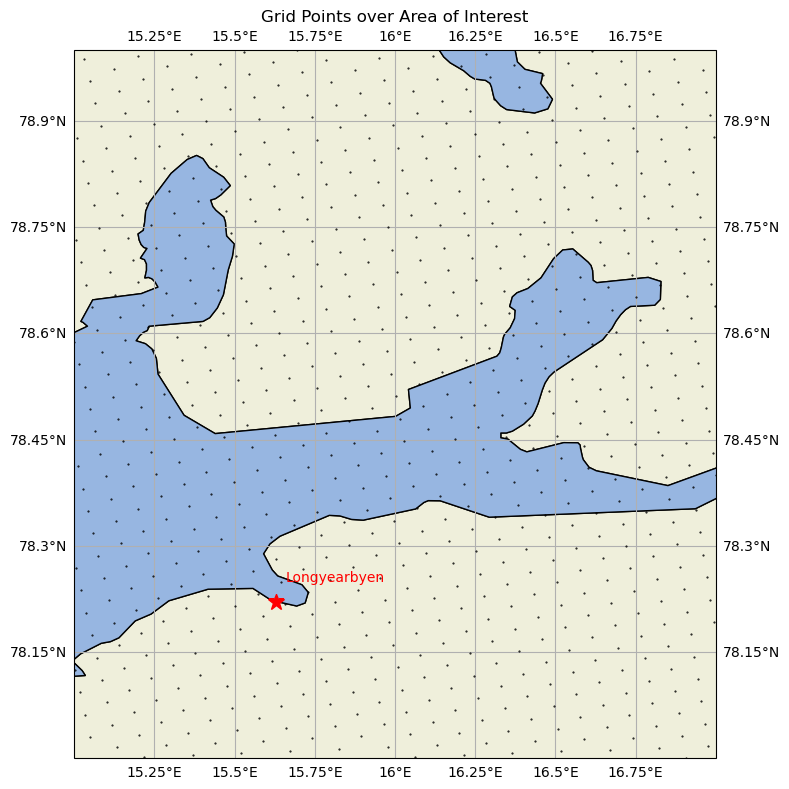

In [ ]:
import xarray as xr
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt
import metpy as mp
import cartopy.crs as ccrs
import cartopy.feature as cfeature


file_path = 'https://thredds.met.no/thredds/dodsC/aromearcticlatest/latest/arome_arctic_lagged_6_h_latest_2_5km_latest.nc'

ignore_vars = [#'time', 'forecast_reference_time', 
    'ensemble_member', #'pressure', 'height_above_msl', 'height0', 'height1', 'height2', 'projection_lambert', 'x', 'y', 'longitude', 'latitude', 
    #'x_wind_pl', 'y_wind_pl', 'air_temperature_pl', 'air_temperature_2m', 'relative_humidity_2m', 'x_wind_10m', 'y_wind_10m', 
    'cloud_area_fraction', 'air_pressure_at_sea_level', 'precipitation_amount_acc', 'snowfall_amount_acc', 'wind_speed_of_gust', 'fog_area_fraction']

area_of_interest = {
    'lat_min': 78.0,
    'lat_max': 79.0,
    'lon_min': 15.0,
    'lon_max': 17.0
}

# Load the dataset
ds = xr.open_dataset(file_path, drop_variables=ignore_vars).sel(ensemble_member=0)

# Get latitude and longitude arrays
lat = ds['latitude']
lon = ds['longitude']

# Display the dataset structure
print(ds)


<xarray.Dataset> Size: 5MB
Dimensions:                  (time: 62, pressure: 2, y: 44, x: 42, height0: 1,
                              height2: 1, height_above_msl: 1, height1: 1)
Coordinates:
  * time                     (time) datetime64[ns] 496B 2026-09-30T09:00:00 ....
  * pressure                 (pressure) float32 8B 850.0 925.0
  * y                        (y) float32 176B 3.62e+05 3.645e+05 ... 4.695e+05
  * x                        (x) float32 168B 7.861e+05 7.886e+05 ... 8.886e+05
    longitude                (y, x) float64 15kB 12.7 12.79 ... 19.27 19.35
    latitude                 (y, x) float64 15kB 78.4 78.39 ... 78.57 78.55
  * height0                  (height0) float32 4B 2.0
  * height2                  (height2) float32 4B 10.0
  * height_above_msl         (height_above_msl) float32 4B 0.0
  * height1                  (height1) float32 4B 0.0
Data variables:
    forecast_reference_time  datetime64[ns] 8B ...
    projection_lambert       int32 4B ...
    x_wind_pl   

/opt/homebrew/anaconda3/lib/python3.12/site-packages/shapely/creation.py:460: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, typ, out=out, **kwargs)
/opt/homebrew/anaconda3/lib/python3.12/site-packages/shapely/creation.py:460: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, typ, out=out, **kwargs)


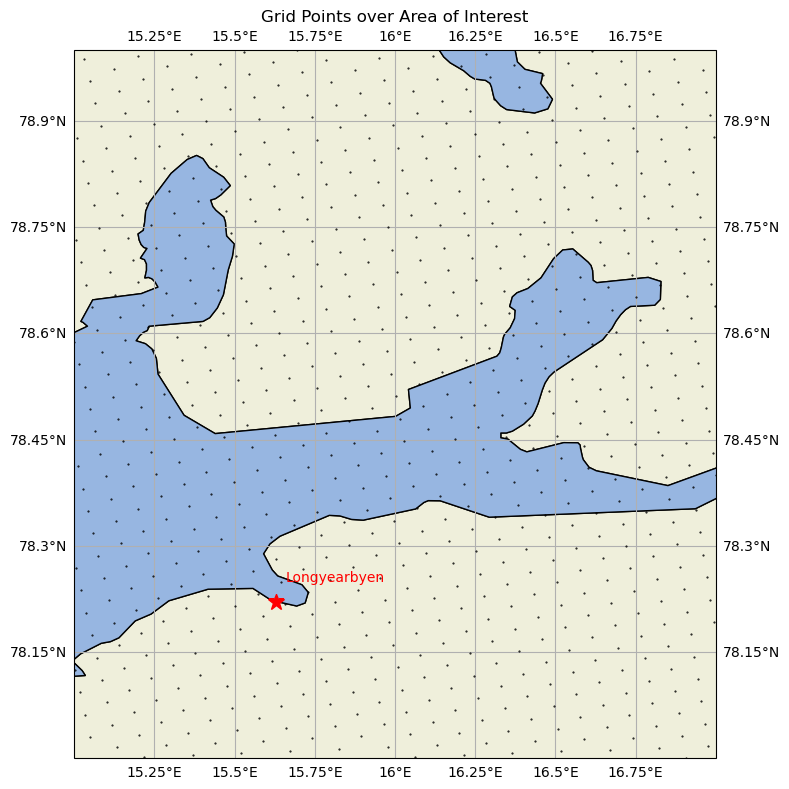

In [3]:

# Create a mask for the area of interest
mask = (
    (lat >= area_of_interest['lat_min']) & (lat <= area_of_interest['lat_max']) &
    (lon >= area_of_interest['lon_min']) & (lon <= area_of_interest['lon_max'])
)

# Find indices where mask is True
y_idx, x_idx = np.where(mask)

# Get the bounding box of x and y indices
if len(x_idx) > 0 and len(y_idx) > 0:
    x_min, x_max = x_idx.min(), x_idx.max()
    y_min, y_max = y_idx.min(), y_idx.max()
    ds_area = ds.isel(x=slice(x_min, x_max+1), y=slice(y_min, y_max+1))
else:
    print("No grid points found in area of interest.")
    ds_area = None

# Display the dataset structure for the area of interest
if ds_area is not None:
    print(ds_area)

#%% Example: Plotting height above MSL for the area of interest with map overlay

if ds_area is not None:
    lats = ds_area['latitude'].values.flatten()
    lons = ds_area['longitude'].values.flatten()

    plt.figure(figsize=(8, 8))  # Make figure square for 1:1 aspect
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.set_extent([area_of_interest['lon_min'], area_of_interest['lon_max'],
                   area_of_interest['lat_min'], area_of_interest['lat_max']], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE)
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    ax.add_feature(cfeature.LAND, edgecolor='black')
    ax.add_feature(cfeature.OCEAN)
    ax.gridlines(draw_labels=True)


    ax.plot(lons, lats, 'k.', markersize=1, transform=ccrs.PlateCarree())

    # add Longyearbyen
    longyearbyen_lon = 15.63
    longyearbyen_lat = 78.22
    
    ax.plot(
    longyearbyen_lon,
    longyearbyen_lat,
    marker='*',
    color='red',
    markersize=12,
    transform=ccrs.PlateCarree(),
    zorder=10
)

    ax.text(
    longyearbyen_lon + 0.03,
    longyearbyen_lat + 0.03,
    'Longyearbyen',
    color='red',
    fontsize=10,
    transform=ccrs.PlateCarree(),
    zorder=10
)

    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.title('Grid Points over Area of Interest')
    ax.set_aspect('auto')  # Ensures the map projection keeps correct aspect
    plt.tight_layout()
    plt.show()
